# Ejercicio 4: Regresión lineal múltiple — PETFOOD

## Enunciado

El gerente de marketing de una cadena de supermercados quiere determinar el efecto que tienen sobre la venta de comida para mascotas (en miles de dólares), el espacio (en metros), y el hecho de que el producto se ubique al frente o al final del pasillo. Se selecciona una muestra compuesta por 12 tiendas del mismo tamaño, que arrojó los resultados del archivo `../Docs/PETFOOD.xls`.

## Resolución paso a paso

1. **Identificar las variables.** `Sales` es la venta de comida para mascotas en miles de dólares; `Space` es el espacio asignado al producto en metros; `Place` indica su ubicación en el pasillo. La muestra contiene 12 tiendas.
2. **Tratar la ubicación como categórica.** En la hoja de datos, `Place` está codificada como 0 o 1, por lo que se usa como variable indicadora. El archivo no explica si 0 o 1 representa el frente o el final del pasillo. El modelo estimará y reportará la diferencia entre Place=1 y Place=0; consulta la codificación original antes de asignarles esas etiquetas.
3. **Ajustar el modelo.** Se estima por mínimos cuadrados $Sales_i = \beta_0 + \beta_1 Space_i + \beta_2 Place_i + \varepsilon_i$. Así, $\beta_1$ mide el cambio asociado a un metro adicional, manteniendo fija la ubicación, y $\beta_2$ compara Place=1 con Place=0, manteniendo fijo el espacio.
4. **Evaluar los resultados.** El código presenta coeficientes, errores estándar, pruebas t, intervalos de confianza y $R^2$. Un intervalo del coeficiente de `Place` que no incluya cero, junto con un p-valor menor que el nivel de significación elegido, indica evidencia de una diferencia entre las dos categorías, controlando por espacio.
5. **Revisar los gráficos.** El gráfico de ventas y espacio distingue las dos ubicaciones e incluye las rectas ajustadas. Los gráficos de observados vs. ajustados y de residuos, además del histograma y gráfico Q-Q, ayudan a revisar visualmente el ajuste. Con 12 tiendas, estas revisiones tienen alcance limitado. La independencia se sustenta en el diseño; los gráficos no la prueban.

El análisis describe asociaciones ajustadas entre ventas, espacio y ubicación; no demuestra causalidad. La interpretación de los coeficientes y pruebas depende de que el modelo lineal y los supuestos de los residuos sean razonables.

Archivo: C:\Users\Gasti\Desktop\MPG\Docs\PETFOOD.xls
Tiendas: 12
Sales: miles de USD | Space: metros | Place: códigos 0 y 1
Nota: el archivo no identifica cuál código corresponde al frente o al final del pasillo.


,Sales,Space,Place
0,1.6,5,0
1,2.2,5,1
2,1.4,5,0
3,1.9,10,0
4,2.4,10,0
5,2.6,10,1
6,2.3,15,0
7,2.7,15,0
8,2.8,15,1
9,2.6,20,0


,Coeficiente,Error estándar,t,p-valor,IC 95% inferior,IC 95% superior
Intercepto,1.300,0.156894,8.285847,0.000017,0.945081,1.654919
Space (por metro),0.074,0.011008,6.722131,0.000086,0.049097,0.098903
Place=1 vs. Place=0,0.450,0.130544,3.447121,0.007308,0.154690,0.745310


R² = 0.8638 | R² ajustado = 0.8335 | Error estándar residual = 0.2132 miles de USD
Ecuación estimada: Sales_hat = 1.300 + 0.074·Space + 0.450·Place
Por cada metro adicional, las ventas estimadas cambian en 0.074 miles de USD, manteniendo Place constante.
Place=1 tiene ventas estimadas 0.450 miles de USD mayores que Place=0, manteniendo Space constante.
Para el efecto de Place: IC 95% [0.155, 0.745] miles de USD; p-valor = 0.0073.


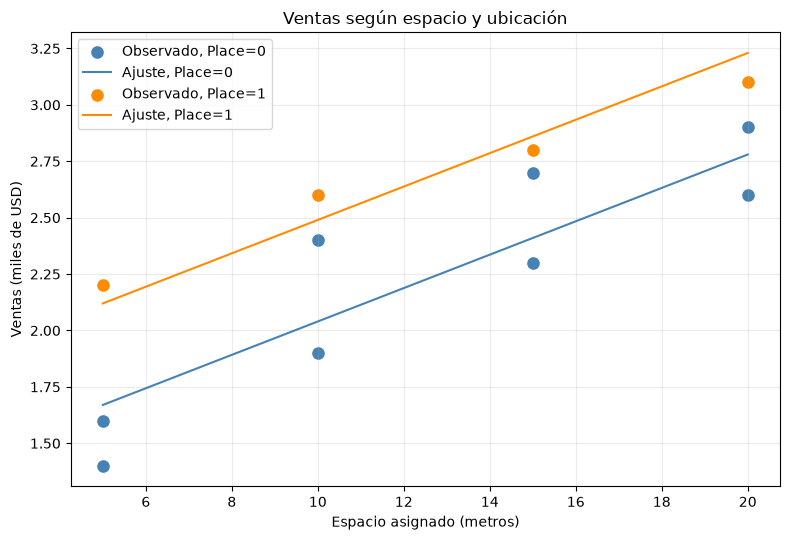

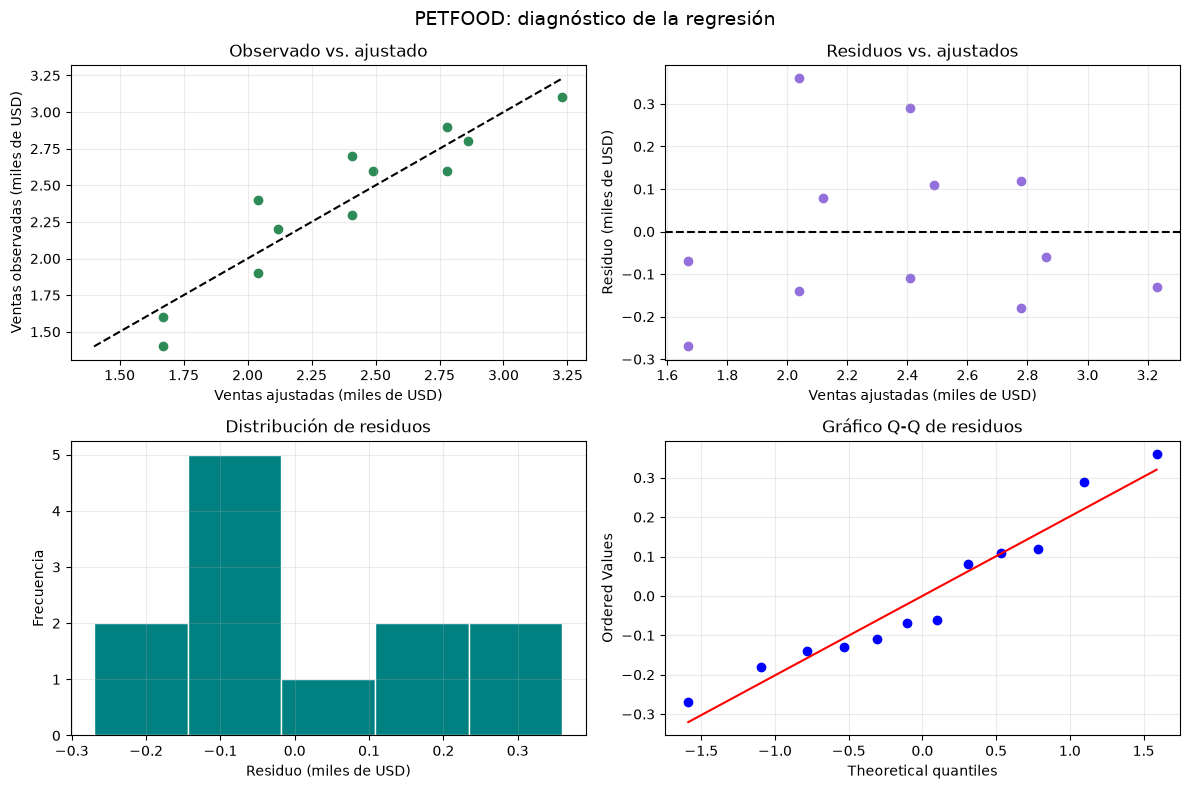

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

# Busca el archivo desde la raíz del proyecto o desde Regresion_lineal.
rutas = [Path("Docs/PETFOOD.xls"), Path("../Docs/PETFOOD.xls")]
archivo = next((ruta for ruta in rutas if ruta.is_file()), None)
if archivo is None:
    raise FileNotFoundError(
        "No se encontró PETFOOD.xls. Comprueba que el archivo esté en la carpeta Docs del proyecto."
    )

datos = pd.read_excel(archivo)
columnas = ["Sales", "Space", "Place"]
faltantes = set(columnas).difference(datos.columns)
if faltantes:
    raise ValueError(f"Faltan columnas en PETFOOD.xls: {sorted(faltantes)}")
if len(datos) != 12 or datos[columnas].isna().any().any():
    raise ValueError("Se esperaban 12 observaciones completas en Sales, Space y Place.")
niveles_place = sorted(datos["Place"].unique())
if niveles_place != [0, 1]:
    raise ValueError(f"Se esperaba que Place tuviera códigos 0 y 1; se encontraron {niveles_place}.")

print(f"Archivo: {archivo.resolve()}")
print(f"Tiendas: {len(datos)}")
print("Sales: miles de USD | Space: metros | Place: códigos 0 y 1")
print("Nota: el archivo no identifica cuál código corresponde al frente o al final del pasillo.")
display(datos)

# Regresión: Sales = beta_0 + beta_1*Space + beta_2*Place + error.
y = datos["Sales"].to_numpy(dtype=float)
X = np.column_stack(
    [np.ones(len(datos)), datos["Space"].to_numpy(dtype=float), datos["Place"].to_numpy(dtype=float)]
)
n, k = X.shape
gl_error = n - k
beta, _, _, _ = np.linalg.lstsq(X, y, rcond=None)
ajustados = X @ beta
residuos = y - ajustados
sse = float(residuos @ residuos)
mse = sse / gl_error
cov_beta = mse * np.linalg.inv(X.T @ X)
ee_beta = np.sqrt(np.diag(cov_beta))
t_beta = beta / ee_beta
p_beta = 2 * stats.t.sf(np.abs(t_beta), gl_error)
t_critico = stats.t.ppf(0.975, gl_error)
li_beta = beta - t_critico * ee_beta
ls_beta = beta + t_critico * ee_beta
r2 = 1 - sse / np.sum((y - y.mean()) ** 2)
r2_ajustado = 1 - (1 - r2) * (n - 1) / gl_error

tabla = pd.DataFrame(
    {
        "Coeficiente": beta,
        "Error estándar": ee_beta,
        "t": t_beta,
        "p-valor": p_beta,
        "IC 95% inferior": li_beta,
        "IC 95% superior": ls_beta,
    },
    index=["Intercepto", "Space (por metro)", "Place=1 vs. Place=0"],
)
display(tabla)
print(f"R² = {r2:.4f} | R² ajustado = {r2_ajustado:.4f} | Error estándar residual = {np.sqrt(mse):.4f} miles de USD")
print(f"Ecuación estimada: Sales_hat = {beta[0]:.3f} + {beta[1]:.3f}·Space + {beta[2]:.3f}·Place")
print(f"Por cada metro adicional, las ventas estimadas cambian en {beta[1]:.3f} miles de USD, manteniendo Place constante.")
print(f"Place=1 tiene ventas estimadas {beta[2]:.3f} miles de USD mayores que Place=0, manteniendo Space constante.")
print(f"Para el efecto de Place: IC 95% [{li_beta[2]:.3f}, {ls_beta[2]:.3f}] miles de USD; p-valor = {p_beta[2]:.4f}.")

# Rectas de regresión estimadas para ambas ubicaciones, sobre el rango observado.
espacios = np.linspace(datos["Space"].min(), datos["Space"].max(), 100)
fig, ax = plt.subplots(figsize=(8, 5.5))
colores = {0: "steelblue", 1: "darkorange"}
for place in niveles_place:
    grupo = datos[datos["Place"] == place]
    ax.scatter(grupo["Space"], grupo["Sales"], color=colores[place], s=65, label=f"Observado, Place={place}")
    ventas_ajustadas = beta[0] + beta[1] * espacios + beta[2] * place
    ax.plot(espacios, ventas_ajustadas, color=colores[place], label=f"Ajuste, Place={place}")
ax.set(title="Ventas según espacio y ubicación", xlabel="Espacio asignado (metros)", ylabel="Ventas (miles de USD)")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

# Diagnóstico del ajuste.
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
ax[0, 0].scatter(ajustados, y, color="seagreen")
limites = [min(y.min(), ajustados.min()), max(y.max(), ajustados.max())]
ax[0, 0].plot(limites, limites, "k--")
ax[0, 0].set(title="Observado vs. ajustado", xlabel="Ventas ajustadas (miles de USD)", ylabel="Ventas observadas (miles de USD)")
ax[0, 1].scatter(ajustados, residuos, color="mediumpurple")
ax[0, 1].axhline(0, color="black", linestyle="--")
ax[0, 1].set(title="Residuos vs. ajustados", xlabel="Ventas ajustadas (miles de USD)", ylabel="Residuo (miles de USD)")
ax[1, 0].hist(residuos, bins="auto", color="teal", edgecolor="white")
ax[1, 0].set(title="Distribución de residuos", xlabel="Residuo (miles de USD)", ylabel="Frecuencia")
stats.probplot(residuos, dist="norm", plot=ax[1, 1])
ax[1, 1].set(title="Gráfico Q-Q de residuos")
for eje in ax.flat:
    eje.grid(alpha=0.25)
fig.suptitle("PETFOOD: diagnóstico de la regresión", fontsize=14)
fig.tight_layout()
plt.show()

## Conclusión

El modelo estima cómo se asocian el espacio del producto y su ubicación con las ventas, controlando cada variable por la otra. El código informa el cambio de ventas asociado a cada metro adicional y la diferencia de ventas entre Place=1 y Place=0, junto con intervalos de confianza del 95% y p-valores. La hoja de datos no especifica si Place=0 o Place=1 corresponde al frente o al final del pasillo; por ello no se asignan esos nombres sin verificar la codificación original.